In [1]:
%pip install -q pandas numpy matplotlib seaborn transformers torch

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'figure.autolayout': True})
print("Environment ready for evaluation.")

Environment ready for evaluation.


In [5]:

# Upload input files and mount Google Drive for persistent outputs

from google.colab import files, drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Create persistent output folder
OUT_DIR = "/content/drive/MyDrive/RAG project"
os.makedirs(OUT_DIR, exist_ok=True)

# 3. Upload input CSV files
uploaded = files.upload()

# 4. Automatically detect the uploaded files
gen_file = next(
    (name for name in uploaded
     if 'generation' in name.lower() or 'module_3' in name.lower()),
    None
)

query_file = next(
    (name for name in uploaded
     if 'question' in name.lower() or 'query' in name.lower()),
    None
)

if gen_file is None:
    raise FileNotFoundError(
        "Generation results CSV not found. Upload module_3_generation_results.csv."
    )

if query_file is None:
    raise FileNotFoundError(
        "Question set CSV not found. Upload your evaluation questions CSV."
    )

# 5. Load the input data
generation_results = pd.read_csv(gen_file)
questions_df = pd.read_csv(query_file)

print(f"Loaded Generation Results: {generation_results.shape}")
print(f"Loaded Query Set: {questions_df.shape}")
print(f"Generation file: {gen_file}")
print(f"Question file: {query_file}")
print(f"Persistent output folder: {OUT_DIR}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving module_3_generation_results (1).csv to module_3_generation_results (1).csv
Saving evaluation_questions - module1_query_set.csv to evaluation_questions - module1_query_set (1).csv
Loaded Generation Results: (2400, 18)
Loaded Query Set: (30, 8)
Generation file: module_3_generation_results (1).csv
Question file: evaluation_questions - module1_query_set (1).csv
Persistent output folder: /content/drive/MyDrive/RAG project


In [6]:
# 1. Merge Datasets and Compute True Recall@K
eval_df = generation_results.merge(
    questions_df[['query_id', 'question', 'category', 'expected_answer', 'supporting_paper_ids', 'supporting_sections', 'answerability']],
    left_on='query',
    right_on='question',
    how='left'
)

def compute_recall(row):
    try:
        retrieved_papers = json.loads(row['retrieved_paper_ids'])
    except:
        retrieved_papers = []

    sup_raw = str(row['supporting_paper_ids'])
    sup_papers = [p.strip() for p in sup_raw.replace(';', ',').split(',') if p.strip()]

    # Handle cases where there are no supporting papers defined
    if not sup_papers:
        return 0.0  # or handle unanswerable/no-paper sets appropriately

    hits = sum(1 for p in sup_papers if p in retrieved_papers)
    # Recall@K = Number of relevant supporting papers retrieved / Total supporting papers
    return hits / len(sup_papers)

eval_df['recall_at_k'] = eval_df.apply(compute_recall, axis=1)
print(f"Mean Corrected Recall@K across all configurations: {eval_df['recall_at_k'].mean():.4f}")

Mean Corrected Recall@K across all configurations: 0.6615


In [15]:

# ============================================================
# MODULE 4 — RAG ANSWER JUDGING V4
# Model: Qwen2.5-1.5B-Instruct
# Purpose: Consistent experimental evaluation, not perfect judging
# ============================================================

import os
import re
import gc
import json
import hashlib
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

# ---------------- SETTINGS ----------------

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
OUTPUT_PATH = os.path.join(
    OUT_DIR, "module_4_rag_judgements_v4.csv"
)

TEST_MODE = False      # Test first; switch to False for all rows
TEST_ROWS = 40
BATCH_SIZE = 4         # If CUDA OOM occurs, change to 2
MAX_NEW_TOKENS = 100
MAX_INPUT_TOKENS = 6000
MAX_CONTEXT_CHARS = 5000
SAVE_EVERY_BATCHES = 5

PROMPT_VERSION = "rag_judge_v4_experimental_rubric"

# ---------------- VALIDATE AND PREPARE DATA ----------------

required = ["query", "rag_answer", "retrieved_context"]
missing = [c for c in required
           if c not in generation_results.columns]
if missing:
    raise ValueError(f"Missing columns in generation_results: {missing}")

if "question" not in questions_df.columns or \
   "expected_answer" not in questions_df.columns:
    raise ValueError(
        "questions_df needs 'question' and 'expected_answer' columns."
    )

os.makedirs(OUT_DIR, exist_ok=True)

def safe_text(value):
    if value is None or pd.isna(value):
        return ""
    return str(value)

work = generation_results.copy().reset_index(drop=True)

if "expected_answer" not in work.columns:
    lookup = questions_df[["question", "expected_answer"]].copy()
    lookup["__key"] = lookup["question"].fillna("").astype(str).str.strip()
    lookup = lookup.drop_duplicates("__key")

    work["__key"] = work["query"].fillna("").astype(str).str.strip()
    work = work.merge(
        lookup[["__key", "expected_answer"]],
        on="__key",
        how="left",
        validate="many_to_one"
    )
    work.drop(columns="__key", inplace=True)

if work["expected_answer"].isna().any():
    raise ValueError(
        "Some generation rows have no expected answer. "
        "Check query/question matching before continuing."
    )

# Fingerprint includes all inputs that influence the judgment.
def fingerprint_row(row):
    fields = [
        safe_text(row.get("query", "")),
        safe_text(row.get("expected_answer", "")),
        safe_text(row.get("retrieved_context", "")),
        safe_text(row.get("rag_answer", "")),
        safe_text(row.get("config_id", "")),
        safe_text(row.get("query_id", "")),
    ]
    return hashlib.sha256(
        (PROMPT_VERSION + "\n" + "\n".join(fields)).encode("utf-8")
    ).hexdigest()

work["judge_fingerprint"] = work.apply(fingerprint_row, axis=1)
work["prompt_version"] = PROMPT_VERSION

if TEST_MODE:
    results = work.head(TEST_ROWS).copy()
    print(f"TEST MODE: {len(results)} rows")
else:
    results = work.copy()
    print(f"FULL MODE: {len(results)} rows")

# ---------------- LOAD MODEL ----------------

dtype = torch.float16 if torch.cuda.is_available() else torch.float32

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA unavailable; CPU inference may be slow.")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=dtype,
    device_map="auto"
)
model.eval()

# ---------------- V4 SCORING RUBRIC ----------------

SYSTEM_PROMPT = """You are an evaluator for an experiment studying retrieval-augmented generation (RAG).

Evaluate answer quality and hallucination as two independent scores.

ANSWER QUALITY — compare the answer with the question and reference answer:
2 = Correct and sufficiently answers the question. Different wording is acceptable.
1 = Partly correct, incomplete, vague, or contains a meaningful error, but still addresses part of the question.
0 = Incorrect, irrelevant, answers a different question, or fails to provide a meaningful answer.

Judge the substance of the answer, not whether it sounds fluent or mentions related terms.
An answer that names the wrong architecture or confuses a system's purpose with a related task is not fully correct.
For multi-part questions, check whether the important parts are addressed.
Use the reference answer as the expected core information, not as a requirement for identical wording.

For questions designated unanswerable, an appropriate statement that evidence is insufficient can receive quality 2. A confident unsupported answer should receive 0 or 1 depending on its correctness.

HALLUCINATION — judge factual support using only the retrieved context:
1 = At least one clear factual claim is unsupported by or contradicts the retrieved context.
0 = No clear unsupported or contradicted factual claim is present.

Do not automatically label an incomplete answer as a hallucination.
A claim may be wrong relative to the reference but still not count as a hallucination if the retrieved context supports it. Conversely, a plausible claim may be a hallucination if the context does not support it.

Return exactly one JSON object with these keys:
"answer_quality": integer 0, 1, or 2
"hallucination": integer 0 or 1
"reason": short explanation of both scores

Return no Markdown fences, no extra text, no follow-up, and no second answer."""

def make_messages(row):
    context = safe_text(row["retrieved_context"])[:MAX_CONTEXT_CHARS]

    while True:
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {
                "role": "user",
                "content": (
                    f"QUESTION:\n{safe_text(row['query'])}\n\n"
                    f"REFERENCE ANSWER:\n{safe_text(row['expected_answer'])}\n\n"
                    f"RETRIEVED CONTEXT:\n{context}\n\n"
                    f"RAG ANSWER:\n{safe_text(row['rag_answer'])}\n\n"
                    "Evaluate this answer using the rubric."
                )
            }
        ]

        rendered = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )
        count = len(tokenizer(
            rendered, add_special_tokens=False
        )["input_ids"])

        if count <= MAX_INPUT_TOKENS:
            return messages, context, count

        if not context:
            raise ValueError(
                "Prompt exceeds input limit even without context."
            )

        context = context[:int(len(context) * 0.8)]

# ---------------- STRICT OUTPUT PARSER ----------------

def parse_output(raw):
    text = raw.strip()

    # A code fence is acceptable only if it encloses the entire response.
    if text.startswith("```"):
        text = re.sub(
            r"^```(?:json)?\s*", "", text, count=1,
            flags=re.IGNORECASE
        )
        text = re.sub(r"\s*```$", "", text, count=1)

    try:
        obj = json.loads(text)
    except (json.JSONDecodeError, TypeError):
        return {
            "answer_quality": pd.NA,
            "hallucination": pd.NA,
            "judge_reason": "Invalid JSON or extra text outside JSON.",
            "judge_parse_status": "parse_error"
        }

    if not isinstance(obj, dict) or set(obj.keys()) != {
        "answer_quality", "hallucination", "reason"
    }:
        return {
            "answer_quality": pd.NA,
            "hallucination": pd.NA,
            "judge_reason": "Unexpected JSON schema.",
            "judge_parse_status": "schema_error"
        }

    q, h, reason = (
        obj["answer_quality"], obj["hallucination"], obj["reason"]
    )

    if (
        isinstance(q, bool) or not isinstance(q, int) or q not in (0, 1, 2)
        or isinstance(h, bool) or not isinstance(h, int) or h not in (0, 1)
        or not isinstance(reason, str)
    ):
        return {
            "answer_quality": pd.NA,
            "hallucination": pd.NA,
            "judge_reason": "Invalid score type or value.",
            "judge_parse_status": "schema_error"
        }

    return {
        "answer_quality": q,
        "hallucination": h,
        "judge_reason": reason,
        "judge_parse_status": "ok"
    }

# ---------------- SAFE CHECKPOINT / RESUME ----------------

score_cols = [
    "answer_quality", "hallucination",
    "judge_reason", "judge_parse_status"
]

if os.path.exists(OUTPUT_PATH):
    previous = pd.read_csv(OUTPUT_PATH)

    required_checkpoint = {
        "judge_fingerprint", "prompt_version",
        "answer_quality", "hallucination", "judge_parse_status"
    }

    if required_checkpoint.issubset(previous.columns):
        previous = previous[
            previous["prompt_version"].astype(str) == PROMPT_VERSION
        ].drop_duplicates("judge_fingerprint", keep="last")
        old_lookup = previous.set_index("judge_fingerprint")
        print("Found compatible V4 checkpoint.")
    else:
        old_lookup = pd.DataFrame()
        print("Old file is incompatible; scores will not be reused.")
else:
    old_lookup = pd.DataFrame()

for col in score_cols + [
    "judge_raw_output", "judge_input_tokens", "judge_context_chars_used"
]:
    if col not in results.columns:
        results[col] = pd.NA

pending = []

for idx, row in results.iterrows():
    fp = row["judge_fingerprint"]
    reused = False

    if not old_lookup.empty and fp in old_lookup.index:
        saved = old_lookup.loc[fp]
        if isinstance(saved, pd.DataFrame):
            saved = saved.iloc[-1]

        q = pd.to_numeric(saved.get("answer_quality"), errors="coerce")
        h = pd.to_numeric(saved.get("hallucination"), errors="coerce")

        if (
            pd.notna(q) and int(q) in (0, 1, 2)
            and pd.notna(h) and int(h) in (0, 1)
            and str(saved.get("judge_parse_status", "")) == "ok"
        ):
            for col in score_cols:
                if col in saved.index:
                    results.at[idx, col] = saved[col]
            if "judge_raw_output" in saved.index:
                results.at[idx, "judge_raw_output"] = saved["judge_raw_output"]
            reused = True

    if not reused:
        pending.append(idx)

def save_checkpoint():
    results.to_csv(OUTPUT_PATH, index=False)

print("Previously valid scores reused:", len(results) - len(pending))
print("Rows to judge:", len(pending))

# ---------------- RUN JUDGING ----------------

device = next(model.parameters()).device
batch_num = 0
new_valid = 0
new_failed = 0

for start in tqdm(
    range(0, len(pending), BATCH_SIZE),
    desc="V4 RAG judging"
):
    indices = pending[start:start + BATCH_SIZE]
    prompts = []

    for idx in indices:
        messages, context, token_count = make_messages(results.loc[idx])
        prompts.append(tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        ))
        results.at[idx, "judge_input_tokens"] = token_count
        results.at[idx, "judge_context_chars_used"] = len(context)

    encoded = tokenizer(
        prompts,
        return_tensors="pt",
        padding=True,
        truncation=False
    )
    encoded = {k: v.to(device) for k, v in encoded.items()}
    prompt_width = encoded["input_ids"].shape[1]

    try:
        with torch.inference_mode():
            output_ids = model.generate(
                **encoded,
                max_new_tokens=MAX_NEW_TOKENS,
                do_sample=False,
                num_beams=1,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id
            )

        continuation = output_ids[:, prompt_width:]
        raw_outputs = tokenizer.batch_decode(
            continuation, skip_special_tokens=True
        )

        for idx, raw in zip(indices, raw_outputs):
            parsed = parse_output(raw)
            for col, value in parsed.items():
                results.at[idx, col] = value

            results.at[idx, "judge_raw_output"] = raw

            if parsed["judge_parse_status"] == "ok":
                new_valid += 1
            else:
                new_failed += 1

    except torch.cuda.OutOfMemoryError:
        save_checkpoint()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        raise RuntimeError(
            "GPU out of memory. Checkpoint saved. "
            "Set BATCH_SIZE = 2 and rerun."
        )

    batch_num += 1
    if batch_num % SAVE_EVERY_BATCHES == 0:
        save_checkpoint()

    del encoded, output_ids, continuation, raw_outputs
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

save_checkpoint()

# ---------------- SUMMARY ----------------

print("\nV4 judging complete.")
print("Saved to:", OUTPUT_PATH)
print("Rows:", len(results))
print("New valid judgments:", new_valid)
print("New invalid/malformed judgments:", new_failed)

print("\nQuality distribution:")
print(results["answer_quality"].value_counts(dropna=False).sort_index())

print("\nHallucination distribution:")
print(results["hallucination"].value_counts(dropna=False).sort_index())

print("\nQuality × hallucination:")
display(pd.crosstab(
    results["answer_quality"],
    results["hallucination"],
    dropna=False
))

print("\nSample judgments:")
display(results[
    [
        "query", "expected_answer", "rag_answer",
        "answer_quality", "hallucination",
        "judge_reason", "judge_parse_status"
    ]
].head(10))


FULL MODE: 2400 rows
GPU: Tesla T4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Found compatible V4 checkpoint.
Previously valid scores reused: 39
Rows to judge: 2361


V4 RAG judging:   0%|          | 0/591 [00:00<?, ?it/s]


V4 judging complete.
Saved to: /content/drive/MyDrive/RAG project/module_4_rag_judgements_v4.csv
Rows: 2400
New valid judgments: 2086
New invalid/malformed judgments: 275

Quality distribution:
answer_quality
0.0      295
1.0      514
2.0     1316
<NA>     275
Name: count, dtype: int64

Hallucination distribution:
hallucination
0.0     2116
1          9
<NA>     275
Name: count, dtype: int64

Quality × hallucination:


hallucination,0.0,1.0,NaN
answer_quality,,,
2.0,1316,0,0
NaN,0,0,275
0.0,286,9,0
1.0,514,0,0



Sample judgments:


,query,expected_answer,rag_answer,answer_quality,hallucination,judge_reason,judge_parse_status
0,What problem does Retrieval-Augmented Generati...,RAG combines a parametric language model with ...,Retrieval-Augmented Generation (RAG) aims to a...,2.0,0.0,The answer correctly identifies the primary go...,ok
1,What are the two main components combined in t...,A pre-trained sequence-to-sequence generator a...,The two main components combined in the RAG (R...,2.0,0.0,The answer correctly identifies 'retrieval' an...,ok
2,What task does Dense Passage Retrieval (DPR) t...,Open-domain question answering by retrieving r...,Dense Passage Retrieval (DPR) targets the task...,2.0,0.0,The answer correctly identifies Dense Passage ...,ok
3,What is the main purpose of RAGAS?,To provide automated evaluation of retrieval-a...,"The main purpose of RAGAS, as per the provided...",2.0,0.0,The answer correctly identifies the primary fo...,ok
4,What issue is investigated in 'Lost in the Mid...,The paper investigates how language models use...,The issue investigated in 'Lost in the Middle:...,<NA>,<NA>,Invalid score type or value.,schema_error
5,What architecture is introduced in 'Attention ...,"The Transformer architecture, which is based o...","The architecture introduced in ""Attention Is A...",2.0,0.0,The answer correctly identifies the attention ...,ok
6,"What does BERT stand for, and what kind of rep...",BERT stands for Bidirectional Encoder Represen...,BERT stands for Bidirectional Encoder Represen...,1.0,0.0,The answer correctly identifies BERT as Bidire...,ok
7,What learning setting is demonstrated by GPT-3...,Few-shot learning through in-context examples ...,GPT-3 demonstrates learning in a few-shot sett...,2.0,0.0,The answer correctly identifies that GPT-3 dem...,ok
8,What does LoRA change when adapting a large la...,LoRA adds trainable low-rank matrices to selec...,LoRA changes the weight matrices (δw) of a lar...,2.0,0.0,The answer correctly identifies LoRA as changi...,ok
9,What is the goal of RAGChecker?,To diagnose RAG systems using fine-grained eva...,"The goal of RAGChecker, as described in the pr...",2.0,0.0,The answer correctly identifies the goal of RA...,ok


In [17]:

# MODULE 4 — V4 RETRY CELL
# Retries only rows with missing/invalid RAG judge scores.
# Existing valid scores are preserved.

import os
import json
import re
import time
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Settings
# --------------------------------------------------
OUTPUT_PATH = "/content/drive/MyDrive/RAG project/module_4_rag_judgements_v4.csv"
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

BATCH_SIZE = 4
MAX_NEW_TOKENS = 120
SAVE_EVERY_BATCHES = 5
MAX_CONTEXT_CHARS = 5000

assert os.path.exists(OUTPUT_PATH), (
    f"File not found: {OUTPUT_PATH}. Make sure Google Drive is mounted."
)

df = pd.read_csv(OUTPUT_PATH)

# Ensure score columns exist
for col in ["answer_quality", "hallucination"]:
    if col not in df.columns:
        df[col] = pd.NA

# Treat only permitted score values as valid
quality_num = pd.to_numeric(df["answer_quality"], errors="coerce")
hallucination_num = pd.to_numeric(df["hallucination"], errors="coerce")

valid_quality = quality_num.isin([0, 1, 2])
valid_hallucination = hallucination_num.isin([0, 1])

# Preserve rows only when BOTH scores are valid
retry_mask = ~(valid_quality & valid_hallucination)
retry_indices = df.index[retry_mask].tolist()

print("Total rows:", len(df))
print("Rows needing retry:", len(retry_indices))
print("Rows already fully valid:", len(df) - len(retry_indices))

if not retry_indices:
    print("All rows already have valid scores. Nothing to retry.")

else:
    # --------------------------------------------------
    # 2. Load judge model
    # --------------------------------------------------
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto"
    )
    model.eval()

    def get_value(row, possible_columns, default=""):
        for col in possible_columns:
            if col in row.index and pd.notna(row[col]):
                return str(row[col])
        return default

    def make_prompt(row):
        question = get_value(row, ["query", "question"])
        reference = get_value(
            row, ["expected_answer", "reference_answer", "gold_answer"]
        )
        context = get_value(
            row, ["retrieved_context", "context"]
        )[:MAX_CONTEXT_CHARS]
        answer = get_value(row, ["rag_answer", "answer"])

        prompt = f"""
You are evaluating an answer produced by a Retrieval-Augmented Generation (RAG) system.

Return ONLY one valid JSON object with exactly these keys:
"answer_quality", "hallucination", "reason"

QUESTION:
{question}

REFERENCE ANSWER:
{reference}

RETRIEVED CONTEXT:
{context}

RAG ANSWER:
{answer}

SCORING RULES:

answer_quality:
2 = Correct and sufficiently answers the question, consistent with the reference.
1 = Partly correct, incomplete, or contains a meaningful error.
0 = Incorrect, irrelevant, off-topic, or fails to answer.

hallucination:
1 = The answer contains at least one factual claim that is unsupported by
    or contradicts the retrieved context.
0 = No such unsupported or contradictory claim is identified.

Evaluate the answer, not its writing style. Do not assume a claim is supported
merely because it appears in the reference answer. Use the retrieved context
to judge support for the RAG answer.

Output format example:
{{"answer_quality": 1, "hallucination": 0, "reason": "Brief explanation"}}

Both scores must be integers. Do not include markdown or text outside the JSON.
"""
        return prompt

    def parse_judgment(text):
        # Accept a JSON object even if the model wraps it in whitespace.
        text = text.strip()
        match = re.search(r"\{.*?\}", text, flags=re.DOTALL)

        if not match:
            return None

        try:
            obj = json.loads(match.group(0))
        except json.JSONDecodeError:
            return None

        if not isinstance(obj, dict):
            return None

        q = obj.get("answer_quality")
        h = obj.get("hallucination")

        # Reject booleans, strings, missing values, and out-of-range scores.
        if type(q) is not int or q not in [0, 1, 2]:
            return None
        if type(h) is not int or h not in [0, 1]:
            return None

        return {
            "answer_quality": q,
            "hallucination": h,
            "reason": str(obj.get("reason", "Retry judgment"))[:1000]
        }

    def save_checkpoint():
        df.to_csv(OUTPUT_PATH, index=False)
        print("Checkpoint saved.")

    # --------------------------------------------------
    # 3. Retry unresolved rows only
    # --------------------------------------------------
    newly_valid = 0
    still_invalid = 0
    failed_rows = []

    for batch_start in range(0, len(retry_indices), BATCH_SIZE):
        batch_indices = retry_indices[batch_start:batch_start + BATCH_SIZE]

        for idx in batch_indices:
            prompt = make_prompt(df.loc[idx])

            try:
                messages = [
                    {
                        "role": "system",
                        "content": "You are a careful evaluator. Return only valid JSON."
                    },
                    {"role": "user", "content": prompt}
                ]

                rendered = tokenizer.apply_chat_template(
                    messages,
                    tokenize=False,
                    add_generation_prompt=True
                )

                inputs = tokenizer(
                    rendered,
                    return_tensors="pt",
                    truncation=True,
                    max_length=6000
                ).to(model.device)

                with torch.inference_mode():
                    output = model.generate(
                        **inputs,
                        max_new_tokens=MAX_NEW_TOKENS,
                        do_sample=False,
                        pad_token_id=tokenizer.eos_token_id
                    )

                generated_tokens = output[0][inputs["input_ids"].shape[1]:]
                raw_output = tokenizer.decode(
                    generated_tokens, skip_special_tokens=True
                )

                judgment = parse_judgment(raw_output)

                if judgment is not None:
                    df.at[idx, "answer_quality"] = judgment["answer_quality"]
                    df.at[idx, "hallucination"] = judgment["hallucination"]

                    # Update reason only if a reason column exists
                    if "reason" in df.columns:
                        df.at[idx, "reason"] = judgment["reason"]
                    elif "rag_judge_reason" in df.columns:
                        df.at[idx, "rag_judge_reason"] = judgment["reason"]

                    newly_valid += 1
                else:
                    still_invalid += 1
                    failed_rows.append(idx)

            except Exception as e:
                still_invalid += 1
                failed_rows.append(idx)
                print(f"Row {idx} failed: {str(e)[:180]}")

        batches_done = (batch_start // BATCH_SIZE) + 1

        if batches_done % SAVE_EVERY_BATCHES == 0:
            save_checkpoint()
            print(
                f"Progress: {min(batch_start + BATCH_SIZE, len(retry_indices))}"
                f"/{len(retry_indices)} retry rows processed"
            )

    # --------------------------------------------------
    # 4. Final save and report
    # --------------------------------------------------
    df.to_csv(OUTPUT_PATH, index=False)

    print("\nRetry complete.")
    print("Saved to:", OUTPUT_PATH)
    print("Rows retried:", len(retry_indices))
    print("New valid judgments:", newly_valid)
    print("Still unresolved:", still_invalid)

    quality_final = pd.to_numeric(df["answer_quality"], errors="coerce")
    hallucination_final = pd.to_numeric(df["hallucination"], errors="coerce")

    final_valid = (
        quality_final.isin([0, 1, 2])
        & hallucination_final.isin([0, 1])
    )

    print("Final rows with both valid scores:", int(final_valid.sum()))
    print("Final rows still missing/invalid:", int((~final_valid).sum()))

    print("\nFinal quality distribution:")
    print(quality_final.value_counts(dropna=False).sort_index())

    print("\nFinal hallucination distribution:")
    print(hallucination_final.value_counts(dropna=False).sort_index())

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



Total rows: 2400
Rows needing retry: 275
Rows already fully valid: 2125


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Checkpoint saved.
Progress: 20/275 retry rows processed
Checkpoint saved.
Progress: 40/275 retry rows processed
Checkpoint saved.
Progress: 60/275 retry rows processed
Checkpoint saved.
Progress: 80/275 retry rows processed
Checkpoint saved.
Progress: 100/275 retry rows processed
Checkpoint saved.
Progress: 120/275 retry rows processed
Checkpoint saved.
Progress: 140/275 retry rows processed
Checkpoint saved.
Progress: 160/275 retry rows processed
Checkpoint saved.
Progress: 180/275 retry rows processed
Checkpoint saved.
Progress: 200/275 retry rows processed
Checkpoint saved.
Progress: 220/275 retry rows processed
Checkpoint saved.
Progress: 240/275 retry rows processed
Checkpoint saved.
Progress: 260/275 retry rows processed

Retry complete.
Saved to: /content/drive/MyDrive/RAG project/module_4_rag_judgements_v4.csv
Rows retried: 275
New valid judgments: 265
Still unresolved: 10
Final rows with both valid scores: 2390
Final rows still missing/invalid: 10

Final quality distribution:


In [22]:

# CELL 2 — Judge unique LLM-only / no-RAG answers
# Resumable, with validation for BOTH scores and periodic checkpoints.

import os
import re
import json
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForCausalLM

if "generation_results" not in globals() or "questions_df" not in globals():
    raise RuntimeError("Run the upload-and-mount setup cell first.")
if "OUT_DIR" not in globals():
    raise RuntimeError("OUT_DIR is missing. Run the setup cell first.")

os.makedirs(OUT_DIR, exist_ok=True)
OUT_PATH = os.path.join(OUT_DIR, "module_4_no_rag_judgements.csv")

gen_df = generation_results.copy()
q_df = questions_df.copy()

if "query" not in gen_df.columns or "no_rag_answer" not in gen_df.columns:
    raise ValueError("Generation CSV must contain query and no_rag_answer.")
if "expected_answer" not in q_df.columns:
    raise ValueError("Question CSV must contain expected_answer.")

# Attach reference answers and question metadata
if "query_id" in gen_df.columns and "query_id" in q_df.columns:
    merge_cols = ["query_id", "expected_answer"]
    for c in ["category", "answerability", "reason_unanswerable"]:
        if c in q_df.columns:
            merge_cols.append(c)

    merged = gen_df.merge(
        q_df[merge_cols].drop_duplicates("query_id"),
        on="query_id", how="left", suffixes=("", "_ref"),
        validate="many_to_one"
    )
else:
    if "question" not in q_df.columns:
        raise ValueError("Question CSV must contain question or matching query_id.")

    merge_cols = ["question", "expected_answer"]
    for c in ["category", "answerability", "reason_unanswerable"]:
        if c in q_df.columns:
            merge_cols.append(c)

    merged = gen_df.merge(
        q_df[merge_cols].drop_duplicates("question"),
        left_on="query", right_on="question",
        how="left", suffixes=("", "_ref"),
        validate="many_to_one"
    )

if merged["expected_answer"].isna().any():
    raise ValueError("Some questions did not match reference answers.")

# Confirm that no-RAG answers are consistent across configurations
variation = merged.groupby("query")["no_rag_answer"].nunique(dropna=False)
if (variation > 1).any():
    print("WARNING: No-RAG answers vary across configurations for some questions.")
    print("This cell judges one answer per question; inspect those variations.")
else:
    print("No-RAG answers are constant per question across configurations.")

unique_df = (
    merged.sort_values("query")
    .drop_duplicates(subset=["query"])
    .reset_index(drop=True)
)

keep_cols = ["query", "no_rag_answer", "expected_answer"]
for c in ["category", "answerability", "reason_unanswerable"]:
    if c in unique_df.columns:
        keep_cols.append(c)
unique_df = unique_df[keep_cols].copy()

score_cols = [
    "no_rag_answer_quality",
    "no_rag_hallucination",
    "no_rag_judge_reason"
]

# Resume from existing output, matching by query
if os.path.exists(OUT_PATH):
    old = pd.read_csv(OUT_PATH)

    if "query" in old.columns and all(c in old.columns for c in score_cols):
        old_scores = old[["query"] + score_cols].drop_duplicates("query")
        unique_df = unique_df.merge(
            old_scores, on="query", how="left",
            validate="one_to_one"
        )
        print("Loaded existing no-RAG judgments for resuming.")

for c in score_cols:
    if c not in unique_df.columns:
        unique_df[c] = pd.NA

# Strict score validation: only actual integer scores are accepted
def valid_quality_value(x):
    if pd.isna(x):
        return False
    try:
        n = float(x)
        return n in (0, 1, 2)
    except (TypeError, ValueError):
        return False

def valid_hallucination_value(x):
    if pd.isna(x):
        return False
    try:
        n = float(x)
        return n in (0, 1)
    except (TypeError, ValueError):
        return False

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
BATCH_SIZE = 4
MAX_NEW_TOKENS = 140
SAVE_EVERY_BATCHES = 5

def parse_judge_json(text):
    match = re.search(r"\{.*?\}", text, flags=re.S)
    if not match:
        return None

    try:
        obj = json.loads(match.group(0))
    except json.JSONDecodeError:
        return None

    if not isinstance(obj, dict):
        return None

    quality = obj.get("answer_quality")
    hallucination = obj.get("hallucination")

    # Reject strings, floats, booleans, missing or out-of-range values
    if type(quality) is not int or quality not in (0, 1, 2):
        return None
    if type(hallucination) is not int or hallucination not in (0, 1):
        return None

    return {
        "quality": quality,
        "hallucination": hallucination,
        "reason": str(obj.get("reason", ""))[:1000]
    }

def make_no_rag_prompt(row):
    return f"""Evaluate an answer generated by an LLM WITHOUT retrieval.

Question:
{row['query']}

Reference answer:
{row['expected_answer']}

LLM-only answer:
{row['no_rag_answer']}

Score answer_quality:
2 = Correct and sufficiently answers the question.
1 = Partly correct, incomplete, or contains a meaningful error.
0 = Incorrect, irrelevant, or fails to answer.

Score hallucination relative to the reference:
1 = A clear factual claim is contradicted by the reference, or a specific
    factual claim is unsupported by it.
0 = No clear unsupported or contradicted claim relative to the reference.
The reference may not include every valid fact. Do not automatically label
every extra detail as a hallucination.

Return ONLY JSON:
{{"answer_quality": 0, "hallucination": 0, "reason": "brief explanation"}}
"""

# Retry if EITHER score is invalid or missing
pending = []
for i, row in unique_df.iterrows():
    q_ok = valid_quality_value(row["no_rag_answer_quality"])
    h_ok = valid_hallucination_value(row["no_rag_hallucination"])
    answer = row["no_rag_answer"]

    if not (q_ok and h_ok):
        if isinstance(answer, str) and answer.strip():
            pending.append(i)

print(f"Unique questions: {len(unique_df)}")
print(f"No-RAG answers remaining to judge: {len(pending)}")

if pending:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"

    model = AutoModelForCausalLM.from_pretrained(
        MODEL_NAME,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto"
    )
    model.eval()

    def save_checkpoint():
        unique_df.to_csv(OUT_PATH, index=False)
        print("Checkpoint saved:", OUT_PATH)

    for start in range(0, len(pending), BATCH_SIZE):
        idxs = pending[start:start + BATCH_SIZE]
        prompts = []

        for i in idxs:
            messages = [
                {
                    "role": "system",
                    "content": "Evaluate carefully. Return only valid JSON."
                },
                {
                    "role": "user",
                    "content": make_no_rag_prompt(unique_df.loc[i])
                }
            ]
            prompts.append(tokenizer.apply_chat_template(
                messages, tokenize=False, add_generation_prompt=True
            ))

        inputs = tokenizer(
            prompts, return_tensors="pt", padding=True,
            truncation=True, max_length=3000
        ).to(model.device)

        try:
            with torch.inference_mode():
                outputs = model.generate(
                    **inputs,
                    max_new_tokens=MAX_NEW_TOKENS,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id
                )

            prompt_width = inputs["input_ids"].shape[1]
            decoded = tokenizer.batch_decode(
                outputs[:, prompt_width:], skip_special_tokens=True
            )

            for i, raw in zip(idxs, decoded):
                result = parse_judge_json(raw)

                if result is None:
                    # Keep scores unresolved so a later rerun can retry them
                    unique_df.at[i, "no_rag_answer_quality"] = pd.NA
                    unique_df.at[i, "no_rag_hallucination"] = pd.NA
                    unique_df.at[i, "no_rag_judge_reason"] = (
                        "JUDGE_PARSE_ERROR: " + raw[:500]
                    )
                else:
                    unique_df.at[i, "no_rag_answer_quality"] = result["quality"]
                    unique_df.at[i, "no_rag_hallucination"] = result["hallucination"]
                    unique_df.at[i, "no_rag_judge_reason"] = result["reason"]

        except Exception as e:
            print(f"Batch starting at {start} failed: {str(e)[:250]}")
            # Preserve previous valid scores; unresolved rows remain retryable.

        batch_number = start // BATCH_SIZE + 1
        if batch_number % SAVE_EVERY_BATCHES == 0 or start + BATCH_SIZE >= len(pending):
            save_checkpoint()
            done = sum(
                valid_quality_value(x) and valid_hallucination_value(y)
                for x, y in zip(
                    unique_df["no_rag_answer_quality"],
                    unique_df["no_rag_hallucination"]
                )
            )
            print(f"Valid no-RAG judgments: {done}/{len(unique_df)}")

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    save_checkpoint()
    del model, tokenizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

else:
    unique_df.to_csv(OUT_PATH, index=False)
    print("All unique no-RAG answers already have valid scores.")

print("\nCell 2 finished.")
print("Saved to:", OUT_PATH)
print("\nQuality distribution:")
print(unique_df["no_rag_answer_quality"].value_counts(dropna=False).sort_index())
print("\nHallucination distribution:")
print(unique_df["no_rag_hallucination"].value_counts(dropna=False).sort_index())


No-RAG answers are constant per question across configurations.
Unique questions: 30
No-RAG answers remaining to judge: 30


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Checkpoint saved: /content/drive/MyDrive/RAG project/module_4_no_rag_judgements.csv
Valid no-RAG judgments: 20/30
Checkpoint saved: /content/drive/MyDrive/RAG project/module_4_no_rag_judgements.csv
Valid no-RAG judgments: 30/30
Checkpoint saved: /content/drive/MyDrive/RAG project/module_4_no_rag_judgements.csv

Cell 2 finished.
Saved to: /content/drive/MyDrive/RAG project/module_4_no_rag_judgements.csv

Quality distribution:
no_rag_answer_quality
0    21
2     9
Name: count, dtype: int64

Hallucination distribution:
no_rag_hallucination
0    30
Name: count, dtype: int64


DATA CHECK
RAG experiment rows: 2400
Unique no-RAG questions: 30
Unique RAG configurations: 80
Missing RAG quality scores: 10
Missing RAG hallucination scores: 10
Missing no-RAG quality scores: 0
Missing no-RAG hallucination scores: 0
RAG rows without matched no-RAG question: 0

OVERALL COMPARISON


,method,mean_answer_quality,scored_answers,hallucination_flag_rate,hallucination_scored
0,LLM only (no-RAG),0.600000,30,0.000000,30
1,RAG + LLM,1.532636,2390,0.003766,2390


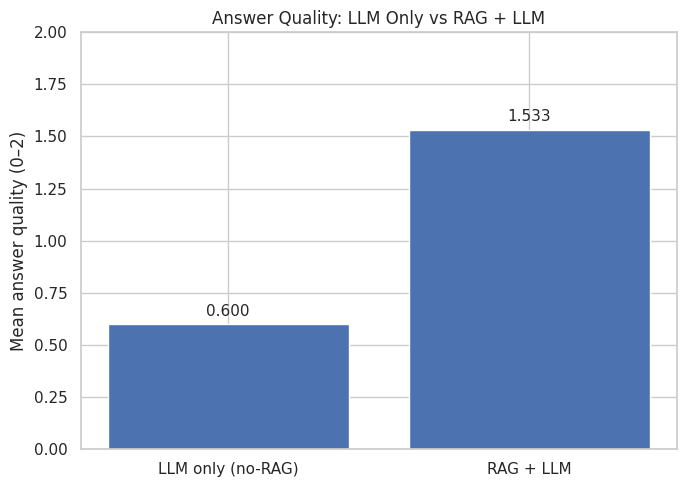

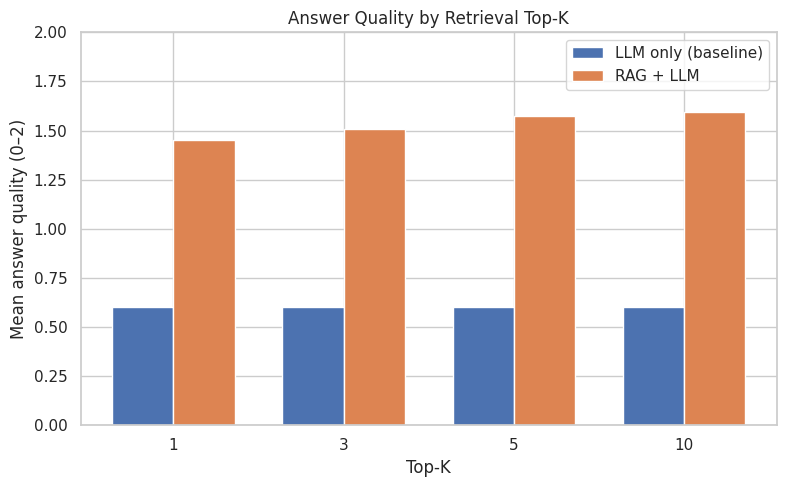


HALLUCINATION SUMMARY


,method,flagged_answers,scored_answers,flag_rate_percent
0,LLM only (no-RAG),0,30,0.000000
1,RAG + LLM,9,2390,0.376569


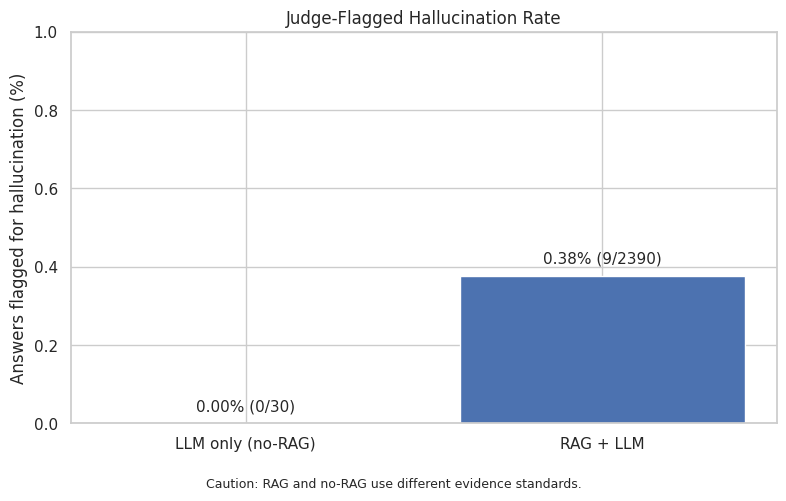

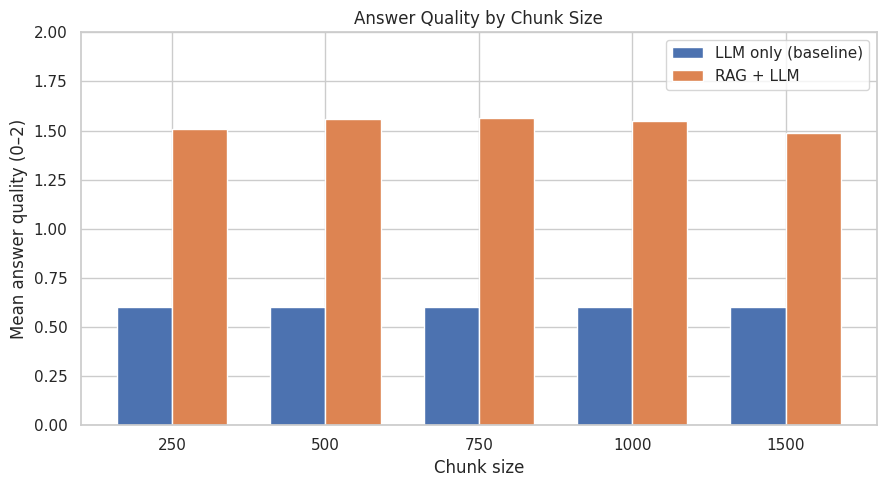


CELL 3 COMPLETE
Combined comparison: /content/drive/MyDrive/RAG project/module_4_rag_vs_no_rag_comparison.csv
Overall summary: /content/drive/MyDrive/RAG project/module_4_overall_comparison_summary.csv
Configuration summary saved.
Graphs and CSV summaries saved in: /content/drive/MyDrive/RAG project


In [24]:

# CELL 3 — RAG vs no-RAG comparison, metrics, summaries and graphs

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# --------------------------------------------------
# 1. Paths and input files
# --------------------------------------------------
OUT_DIR = "/content/drive/MyDrive/RAG project"
os.makedirs(OUT_DIR, exist_ok=True)

RAG_PATH = os.path.join(OUT_DIR, "module_4_rag_judgements_v4.csv")
NO_RAG_PATH = os.path.join(OUT_DIR, "module_4_no_rag_judgements.csv")

for path in [RAG_PATH, NO_RAG_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File not found: {path}\n"
            "Check that Drive is mounted and the judging cells have run."
        )

rag_df = pd.read_csv(RAG_PATH)
no_rag_df = pd.read_csv(NO_RAG_PATH)

# --------------------------------------------------
# 2. Normalize RAG V4 column names
# --------------------------------------------------
rename_map = {
    "answer_quality": "rag_answer_quality",
    "hallucination": "rag_hallucination",
    "reason": "rag_judge_reason"
}

for old_col, new_col in rename_map.items():
    if old_col in rag_df.columns and new_col not in rag_df.columns:
        rag_df.rename(columns={old_col: new_col}, inplace=True)

required_rag = [
    "query", "config_id", "rag_answer_quality", "rag_hallucination"
]
required_no_rag = [
    "query", "no_rag_answer_quality", "no_rag_hallucination"
]

for col in required_rag:
    if col not in rag_df.columns:
        raise ValueError(
            f"RAG file is missing '{col}'.\n"
            f"Available columns: {rag_df.columns.tolist()}"
        )

for col in required_no_rag:
    if col not in no_rag_df.columns:
        raise ValueError(
            f"No-RAG file is missing '{col}'.\n"
            f"Available columns: {no_rag_df.columns.tolist()}"
        )

# --------------------------------------------------
# 3. Clean score values
# Invalid scores remain NaN; never convert them to zero.
# --------------------------------------------------
score_columns = {
    "rag_answer_quality": (0, 1, 2),
    "rag_hallucination": (0, 1),
    "no_rag_answer_quality": (0, 1, 2),
    "no_rag_hallucination": (0, 1)
}

for col, valid_values in score_columns.items():
    if col in rag_df.columns:
        rag_df[col] = pd.to_numeric(rag_df[col], errors="coerce")
    if col in no_rag_df.columns:
        no_rag_df[col] = pd.to_numeric(no_rag_df[col], errors="coerce")

for col, valid_values in score_columns.items():
    target = rag_df if col in rag_df.columns else no_rag_df
    if col in target.columns:
        target.loc[~target[col].isin(valid_values), col] = np.nan

# --------------------------------------------------
# 4. Ensure one no-RAG judgment per question
# --------------------------------------------------
no_rag_scores = no_rag_df[
    ["query", "no_rag_answer_quality", "no_rag_hallucination"]
].drop_duplicates().copy()

if no_rag_scores["query"].duplicated().any():
    raise ValueError(
        "Multiple different no-RAG scores exist for a question. "
        "Resolve duplicates before comparing."
    )

# --------------------------------------------------
# 5. Match baseline scores to each RAG configuration
# --------------------------------------------------
combined = rag_df.merge(
    no_rag_scores,
    on="query",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched = int((combined["_merge"] != "both").sum())
combined.drop(columns=["_merge"], inplace=True)

combined_path = os.path.join(
    OUT_DIR, "module_4_rag_vs_no_rag_comparison.csv"
)
combined.to_csv(combined_path, index=False)

print("=" * 55)
print("DATA CHECK")
print("=" * 55)
print("RAG experiment rows:", len(rag_df))
print("Unique no-RAG questions:", no_rag_scores["query"].nunique())
print("Unique RAG configurations:", rag_df["config_id"].nunique())
print("Missing RAG quality scores:", rag_df["rag_answer_quality"].isna().sum())
print("Missing RAG hallucination scores:", rag_df["rag_hallucination"].isna().sum())
print("Missing no-RAG quality scores:",
      no_rag_scores["no_rag_answer_quality"].isna().sum())
print("Missing no-RAG hallucination scores:",
      no_rag_scores["no_rag_hallucination"].isna().sum())
print("RAG rows without matched no-RAG question:", unmatched)

# --------------------------------------------------
# 6. Overall comparison
# --------------------------------------------------
overall = pd.DataFrame({
    "method": ["LLM only (no-RAG)", "RAG + LLM"],
    "mean_answer_quality": [
        no_rag_scores["no_rag_answer_quality"].mean(),
        rag_df["rag_answer_quality"].mean()
    ],
    "scored_answers": [
        no_rag_scores["no_rag_answer_quality"].count(),
        rag_df["rag_answer_quality"].count()
    ],
    "hallucination_flag_rate": [
        no_rag_scores["no_rag_hallucination"].mean(),
        rag_df["rag_hallucination"].mean()
    ],
    "hallucination_scored": [
        no_rag_scores["no_rag_hallucination"].count(),
        rag_df["rag_hallucination"].count()
    ]
})

overall_path = os.path.join(
    OUT_DIR, "module_4_overall_comparison_summary.csv"
)
overall.to_csv(overall_path, index=False)

print("\nOVERALL COMPARISON")
display(overall)

# --------------------------------------------------
# 7. Graph 1 — Overall mean answer quality
# --------------------------------------------------
plt.figure(figsize=(7, 5))
bars = plt.bar(overall["method"], overall["mean_answer_quality"])
plt.ylabel("Mean answer quality (0–2)")
plt.title("Answer Quality: LLM Only vs RAG + LLM")
plt.ylim(0, 2)

for bar, value in zip(bars, overall["mean_answer_quality"]):
    if pd.notna(value):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.04,
            f"{value:.3f}",
            ha="center"
        )

plt.tight_layout()
plt.savefig(
    os.path.join(OUT_DIR, "graph_overall_answer_quality.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# Shared no-RAG baseline mean
baseline_quality = no_rag_scores["no_rag_answer_quality"].mean()

# --------------------------------------------------
# 8. Graph 2 — Answer quality by Top-K
# --------------------------------------------------
if "top_k" in rag_df.columns:
    by_k = (
        rag_df.groupby("top_k")
        .agg(
            rag_mean_quality=("rag_answer_quality", "mean"),
            rag_scored=("rag_answer_quality", "count")
        )
        .reset_index()
        .sort_values("top_k")
    )

    by_k["no_rag_mean_quality"] = baseline_quality
    by_k.to_csv(
        os.path.join(OUT_DIR, "module_4_quality_by_top_k.csv"),
        index=False
    )

    x = np.arange(len(by_k))
    width = 0.36

    plt.figure(figsize=(8, 5))
    plt.bar(
        x - width / 2,
        [baseline_quality] * len(by_k),
        width,
        label="LLM only (baseline)"
    )
    plt.bar(
        x + width / 2,
        by_k["rag_mean_quality"],
        width,
        label="RAG + LLM"
    )

    plt.xticks(x, by_k["top_k"].astype(str))
    plt.xlabel("Top-K")
    plt.ylabel("Mean answer quality (0–2)")
    plt.title("Answer Quality by Retrieval Top-K")
    plt.ylim(0, 2)
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT_DIR, "graph_quality_by_top_k.png"),
        dpi=200, bbox_inches="tight"
    )
    plt.show()

# --------------------------------------------------
# 9. Graph 3 — Hallucination rate as a percentage
# --------------------------------------------------
# Rate = flagged valid scores / all valid scores.
# Different evidence standards apply to RAG and no-RAG.
hall_methods = ["LLM only (no-RAG)", "RAG + LLM"]

hall_rates = [
    no_rag_scores["no_rag_hallucination"].mean() * 100,
    rag_df["rag_hallucination"].mean() * 100
]

hall_counts = [
    int(no_rag_scores["no_rag_hallucination"].sum()),
    int(rag_df["rag_hallucination"].sum())
]

hall_scored = [
    int(no_rag_scores["no_rag_hallucination"].count()),
    int(rag_df["rag_hallucination"].count())
]

hall_summary = pd.DataFrame({
    "method": hall_methods,
    "flagged_answers": hall_counts,
    "scored_answers": hall_scored,
    "flag_rate_percent": hall_rates
})

hall_summary.to_csv(
    os.path.join(OUT_DIR, "module_4_hallucination_summary.csv"),
    index=False
)

print("\nHALLUCINATION SUMMARY")
display(hall_summary)

plt.figure(figsize=(8, 5))
bars = plt.bar(hall_methods, hall_rates)

# A percentage axis makes the small RAG rate visible.
upper = max(1.0, max(hall_rates) * 1.5)
plt.ylim(0, upper)
plt.ylabel("Answers flagged for hallucination (%)")
plt.title("Judge-Flagged Hallucination Rate")

for bar, rate, count, total in zip(
    bars, hall_rates, hall_counts, hall_scored
):
    label_y = bar.get_height() + upper * 0.025
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        label_y,
        f"{rate:.2f}% ({count}/{total})",
        ha="center",
        va="bottom"
    )

plt.figtext(
    0.5, 0.01,
    "Caution: RAG and no-RAG use different evidence standards.",
    ha="center", fontsize=9
)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    os.path.join(OUT_DIR, "graph_hallucination_rate.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 10. Graph 4 — Answer quality by chunk size
# --------------------------------------------------
if "chunk_size" in rag_df.columns:
    by_chunk = (
        rag_df.groupby("chunk_size")
        .agg(
            rag_mean_quality=("rag_answer_quality", "mean"),
            rag_scored=("rag_answer_quality", "count")
        )
        .reset_index()
        .sort_values("chunk_size")
    )

    by_chunk["no_rag_mean_quality"] = baseline_quality
    by_chunk.to_csv(
        os.path.join(OUT_DIR, "module_4_quality_by_chunk_size.csv"),
        index=False
    )

    x = np.arange(len(by_chunk))
    width = 0.36

    plt.figure(figsize=(9, 5))
    plt.bar(
        x - width / 2,
        [baseline_quality] * len(by_chunk),
        width,
        label="LLM only (baseline)"
    )
    plt.bar(
        x + width / 2,
        by_chunk["rag_mean_quality"],
        width,
        label="RAG + LLM"
    )

    plt.xticks(x, by_chunk["chunk_size"].astype(str))
    plt.xlabel("Chunk size")
    plt.ylabel("Mean answer quality (0–2)")
    plt.title("Answer Quality by Chunk Size")
    plt.ylim(0, 2)
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUT_DIR, "graph_quality_by_chunk_size.png"),
        dpi=200, bbox_inches="tight"
    )
    plt.show()

# --------------------------------------------------
# 11. Per-configuration summary
# --------------------------------------------------
group_cols = ["config_id"]

for col in ["chunk_size", "overlap", "top_k"]:
    if col in combined.columns:
        group_cols.append(col)

config_summary = (
    combined.groupby(group_cols, dropna=False)
    .agg(
        rag_mean_answer_quality=("rag_answer_quality", "mean"),
        rag_quality_scored=("rag_answer_quality", "count"),
        rag_hallucination_flag_rate=("rag_hallucination", "mean"),
        rag_hallucination_scored=("rag_hallucination", "count"),
        no_rag_mean_answer_quality=("no_rag_answer_quality", "mean"),
        no_rag_quality_scored=("no_rag_answer_quality", "count"),
        no_rag_hallucination_flag_rate=("no_rag_hallucination", "mean"),
        no_rag_hallucination_scored=("no_rag_hallucination", "count")
    )
    .reset_index()
)

config_summary.to_csv(
    os.path.join(OUT_DIR, "module_4_configuration_summary.csv"),
    index=False
)

print("\nCELL 3 COMPLETE")
print("Combined comparison:", combined_path)
print("Overall summary:", overall_path)
print("Configuration summary saved.")
print("Graphs and CSV summaries saved in:", OUT_DIR)


In [27]:

# CELL 4 — Merge source data, calculate Recall@K and aggregate metrics

import os
import json
import ast
import numpy as np
import pandas as pd
from IPython.display import display

OUT_DIR = "/content/drive/MyDrive/RAG project"
os.makedirs(OUT_DIR, exist_ok=True)

RAG_PATH = os.path.join(OUT_DIR, "module_4_rag_judgements_v4.csv")
MODULE3_PATH = os.path.join(OUT_DIR, "module_3_generation_results.csv")
QUESTIONS_PATH = os.path.join(OUT_DIR, "evaluation_questions.csv")

# Use already-loaded data when available; otherwise load the CSV.
if "generation_results" in globals():
    generation_df = generation_results.copy()
elif os.path.exists(MODULE3_PATH):
    generation_df = pd.read_csv(MODULE3_PATH)
else:
    raise FileNotFoundError(
        "Module 3 results not found. Set MODULE3_PATH to your actual CSV path."
    )

if "questions_df" in globals():
    questions_df_local = questions_df.copy()
elif os.path.exists(QUESTIONS_PATH):
    questions_df_local = pd.read_csv(QUESTIONS_PATH)
else:
    raise FileNotFoundError(
        "Evaluation question set not found. Set QUESTIONS_PATH to its actual path."
    )

if not os.path.exists(RAG_PATH):
    raise FileNotFoundError(f"RAG judge file not found: {RAG_PATH}")

eval_df = pd.read_csv(RAG_PATH)

# --------------------------------------------------
# 1. Normalize V4 judge score names
# --------------------------------------------------
rename_map = {
    "answer_quality": "rag_answer_quality",
    "hallucination": "rag_hallucination",
    "reason": "rag_judge_reason"
}
for old, new in rename_map.items():
    if old in eval_df.columns and new not in eval_df.columns:
        eval_df.rename(columns={old: new}, inplace=True)

# --------------------------------------------------
# 2. Bring retrieval information from Module 3
# --------------------------------------------------
retrieval_cols = [
    "query", "config_id", "retrieved_paper_ids", "retrieved_context"
]
missing = [c for c in retrieval_cols if c not in generation_df.columns]
if missing:
    raise ValueError(f"Module 3 data is missing columns: {missing}")

# Preserve the original generation metadata too, when available.
for c in ["chunk_size", "overlap", "top_k", "query_id",
          "num_retrieved_chunks", "retrieved_parent_chunk_ids",
          "retrieved_window_ids", "similarity_scores"]:
    if c in generation_df.columns and c not in retrieval_cols:
        retrieval_cols.append(c)

# Each configuration/query combination should appear once.
if generation_df.duplicated(["config_id", "query"]).any():
    raise ValueError(
        "Module 3 has duplicate config_id/query pairs; resolve duplicates before merging."
    )

# Avoid duplicate metadata columns in the judge output.
source_cols = [
    c for c in retrieval_cols
    if c not in eval_df.columns or c in ["query", "config_id"]
]
eval_df = eval_df.merge(
    generation_df[source_cols].drop_duplicates(["config_id", "query"]),
    on=["config_id", "query"],
    how="left",
    validate="one_to_one"
)

# --------------------------------------------------
# 3. Attach reference paper IDs and answerability
# --------------------------------------------------
if "query_id" in eval_df.columns and "query_id" in questions_df_local.columns:
    question_key = "query_id"
    question_cols = [
        c for c in [
            "query_id", "supporting_paper_ids", "supporting_sections",
            "answerability", "category", "expected_answer"
        ]
        if c in questions_df_local.columns
    ]
    question_data = questions_df_local[question_cols].drop_duplicates("query_id")

    eval_df = eval_df.merge(
        question_data,
        on="query_id",
        how="left",
        suffixes=("", "_question"),
        validate="many_to_one"
    )
else:
    # The query text in Module 3 corresponds to the question text in Module 1.
    question_cols = [
        c for c in [
            "question", "supporting_paper_ids", "supporting_sections",
            "answerability", "category", "expected_answer"
        ]
        if c in questions_df_local.columns
    ]
    question_data = questions_df_local[question_cols].drop_duplicates("question")

    eval_df = eval_df.merge(
        question_data,
        left_on="query",
        right_on="question",
        how="left",
        suffixes=("", "_question"),
        validate="many_to_one"
    )

# --------------------------------------------------
# 4. Context size
# --------------------------------------------------
eval_df["retrieved_context"] = (
    eval_df["retrieved_context"].fillna("").astype(str)
)
eval_df["context_char_length"] = eval_df["retrieved_context"].str.len()
eval_df["context_word_count"] = (
    eval_df["retrieved_context"].str.split().str.len()
)

# --------------------------------------------------
# 5. Parse paper ID lists
# --------------------------------------------------
def parse_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    text = str(value).strip()
    if not text:
        return []

    try:
        parsed = json.loads(text)
        return parsed if isinstance(parsed, list) else [parsed]
    except Exception:
        try:
            parsed = ast.literal_eval(text)
            return parsed if isinstance(parsed, list) else [parsed]
        except Exception:
            return [
                x.strip().strip("'\"")
                for x in text.split(",")
                if x.strip()
            ]

def normalize_id(value):
    return str(value).strip().strip("'\"")

# --------------------------------------------------
# 6. Calculate paper-level Recall@K
# --------------------------------------------------
def calculate_recall(row):
    answerability = str(row.get("answerability", "")).strip().lower()

    if answerability in {"unanswerable", "unanswerable question"}:
        return np.nan

    retrieved = {
        normalize_id(x)
        for x in parse_list(row["retrieved_paper_ids"])
        if normalize_id(x)
    }
    supporting = {
        normalize_id(x)
        for x in parse_list(row["supporting_paper_ids"])
        if normalize_id(x)
    }

    # No reference supporting papers means recall is undefined.
    if not supporting:
        return np.nan

    return len(retrieved & supporting) / len(supporting)

if "retrieved_paper_ids" not in eval_df.columns:
    raise ValueError("retrieved_paper_ids was not successfully merged.")
if "supporting_paper_ids" not in eval_df.columns:
    raise ValueError("supporting_paper_ids was not successfully merged.")

eval_df["recall_at_k"] = eval_df.apply(calculate_recall, axis=1)

# --------------------------------------------------
# 7. Validate scores; unresolved judgments stay missing
# --------------------------------------------------
for col, allowed in {
    "rag_answer_quality": [0, 1, 2],
    "rag_hallucination": [0, 1]
}.items():
    if col not in eval_df.columns:
        raise ValueError(f"Missing judge score column: {col}")
    eval_df[col] = pd.to_numeric(eval_df[col], errors="coerce")
    eval_df.loc[~eval_df[col].isin(allowed), col] = np.nan

# --------------------------------------------------
# 8. Aggregate by configuration
# --------------------------------------------------
group_cols = ["config_id"]
for c in ["chunk_size", "overlap", "top_k"]:
    if c in eval_df.columns:
        group_cols.append(c)

summary_df = eval_df.groupby(group_cols, dropna=False).agg(
    mean_recall=("recall_at_k", "mean"),
    recall_scored=("recall_at_k", "count"),
    mean_answer_quality=("rag_answer_quality", "mean"),
    quality_scored=("rag_answer_quality", "count"),
    hallucination_percentage=(
        "rag_hallucination", lambda x: x.mean() * 100
    ),
    hallucination_scored=("rag_hallucination", "count"),
    mean_context_length=("context_char_length", "mean"),
    mean_context_words=("context_word_count", "mean"),
    total_rows=("query", "count")
).reset_index()

# --------------------------------------------------
# 9. Save results
# --------------------------------------------------
DETAIL_PATH = os.path.join(OUT_DIR, "module_4_evaluation_results.csv")
SUMMARY_PATH = os.path.join(OUT_DIR, "module_4_summary_results.csv")

eval_df.to_csv(DETAIL_PATH, index=False, encoding="utf-8-sig")
summary_df.to_csv(SUMMARY_PATH, index=False, encoding="utf-8-sig")

print("Rows:", len(eval_df))
print("Rows with retrieval paper IDs:", eval_df["retrieved_paper_ids"].notna().sum())
print("Rows with supporting paper IDs:", eval_df["supporting_paper_ids"].notna().sum())
print("Rows with valid Recall@K:", eval_df["recall_at_k"].count())
print("Rows with valid quality scores:", eval_df["rag_answer_quality"].count())
print("Unanswerable questions excluded from recall:",
      (eval_df["answerability"].astype(str).str.lower()
       .isin(["unanswerable", "unanswerable question"])).sum())

display(summary_df.head(10))

print("\nDetailed results saved:", DETAIL_PATH)
print("Configuration summary saved:", SUMMARY_PATH)


Rows: 2400
Rows with retrieval paper IDs: 2400
Rows with supporting paper IDs: 2400
Rows with valid Recall@K: 2400
Rows with valid quality scores: 2390
Unanswerable questions excluded from recall: 0


,config_id,chunk_size,overlap,top_k,mean_recall,recall_scored,mean_answer_quality,quality_scored,hallucination_percentage,hallucination_scored,mean_context_length,mean_context_words,total_rows
0,CFG_001,250,0,1,0.300000,30,1.500000,30,0.000000,30,959.833333,166.566667,30
1,CFG_002,250,0,3,0.366667,30,1.433333,30,0.000000,30,3031.600000,520.766667,30
2,CFG_003,250,0,5,0.433333,30,1.466667,30,0.000000,30,5100.100000,883.433333,30
3,CFG_004,250,0,10,0.466667,30,1.600000,30,0.000000,30,10422.566667,1770.600000,30
4,CFG_005,250,50,1,0.300000,30,1.366667,30,0.000000,30,1013.800000,174.533333,30
5,CFG_006,250,50,3,0.366667,30,1.466667,30,3.333333,30,3204.633333,551.866667,30
6,CFG_007,250,50,5,0.433333,30,1.533333,30,0.000000,30,5222.466667,896.600000,30
7,CFG_008,250,50,10,0.466667,30,1.655172,29,0.000000,29,10419.266667,1773.800000,30
8,CFG_009,250,100,1,0.300000,30,1.566667,30,0.000000,30,926.233333,153.100000,30
9,CFG_010,250,100,3,0.400000,30,1.466667,30,0.000000,30,3034.033333,511.700000,30



Detailed results saved: /content/drive/MyDrive/RAG project/module_4_evaluation_results.csv
Configuration summary saved: /content/drive/MyDrive/RAG project/module_4_summary_results.csv


In [28]:
print("Configurations:", len(summary_df))
print("Expected configurations: 80")
print("Recall range:",
      summary_df["mean_recall"].min(),
      "to", summary_df["mean_recall"].max())
print("Missing recall values:", eval_df["recall_at_k"].isna().sum())
print("Missing supporting paper IDs:",
      eval_df["supporting_paper_ids"].isna().sum())
print("Answer-quality scores:",
      eval_df["rag_answer_quality"].value_counts(dropna=False).to_dict())

Configurations: 80
Expected configurations: 80
Recall range: 0.3 to 0.5333333333333333
Missing recall values: 0
Missing supporting paper IDs: 0
Answer-quality scores: {2.0: 1573, 1.0: 517, 0.0: 300, nan: 10}


Configurations: 80
Plots will be saved to: /content/drive/MyDrive/RAG project/evaluation_plots


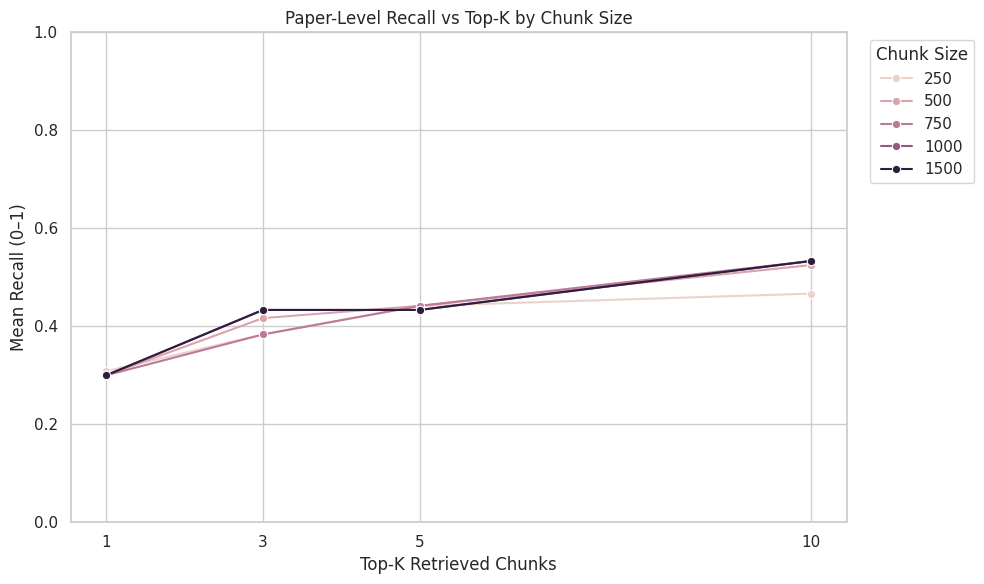

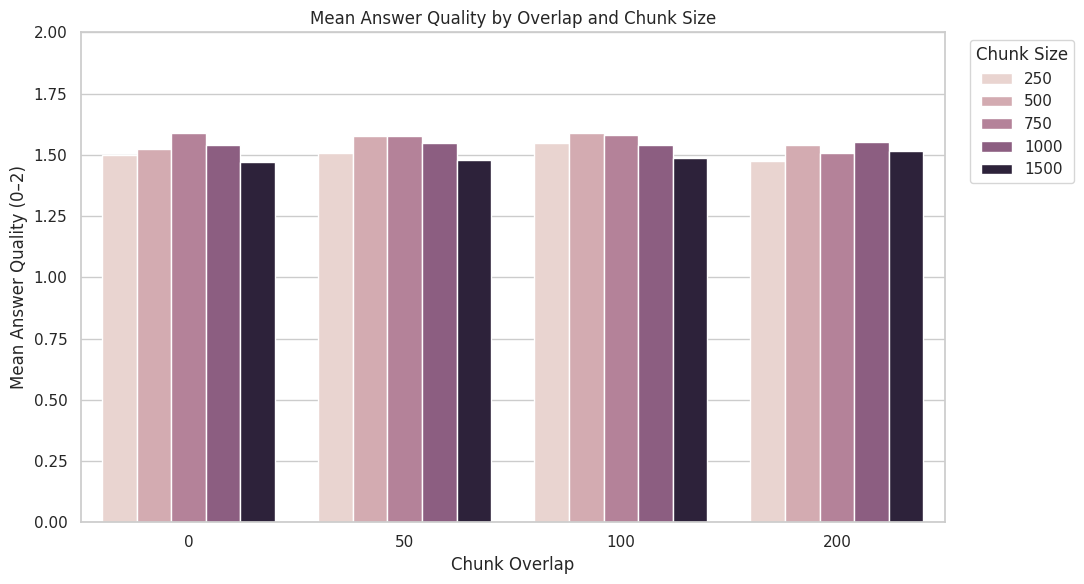

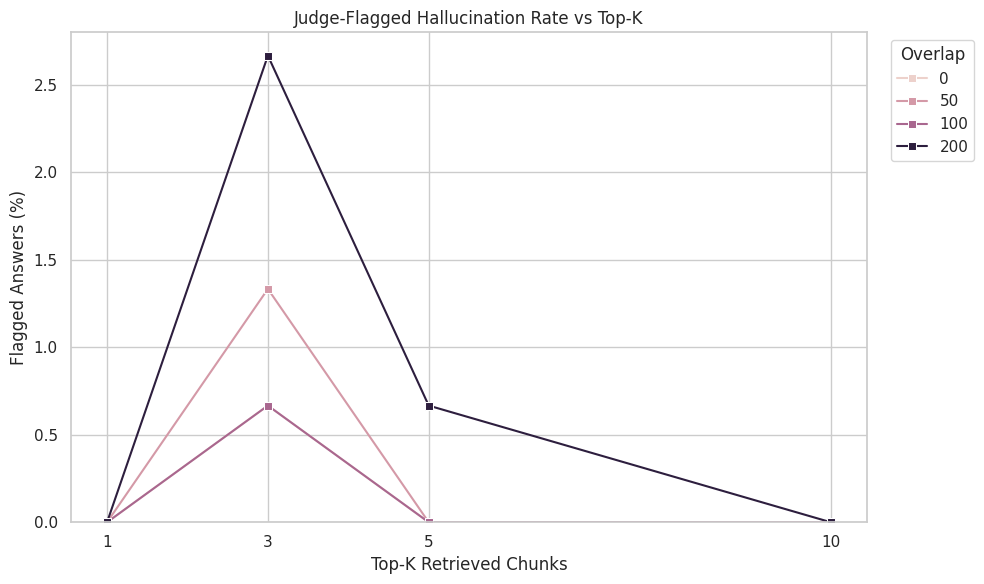

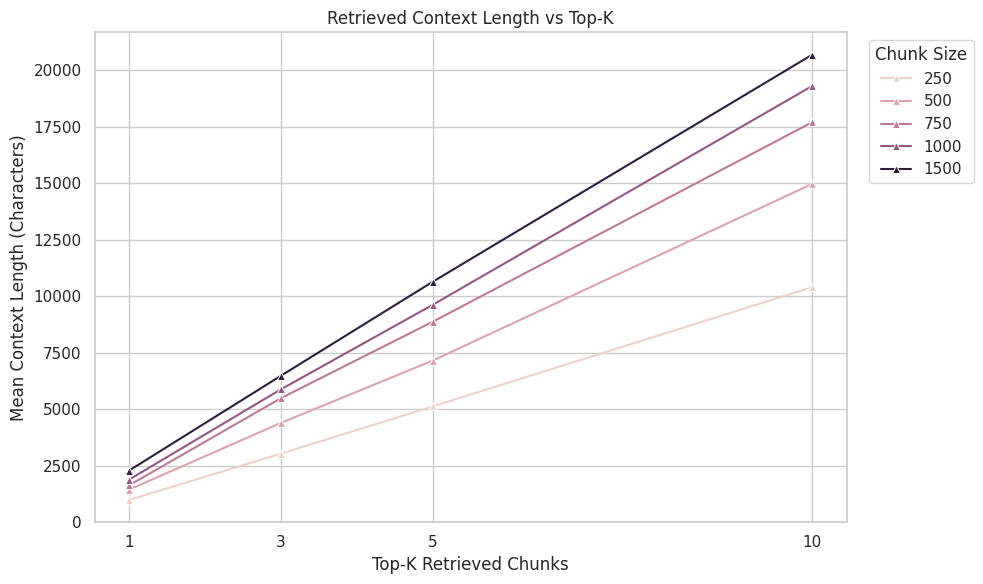

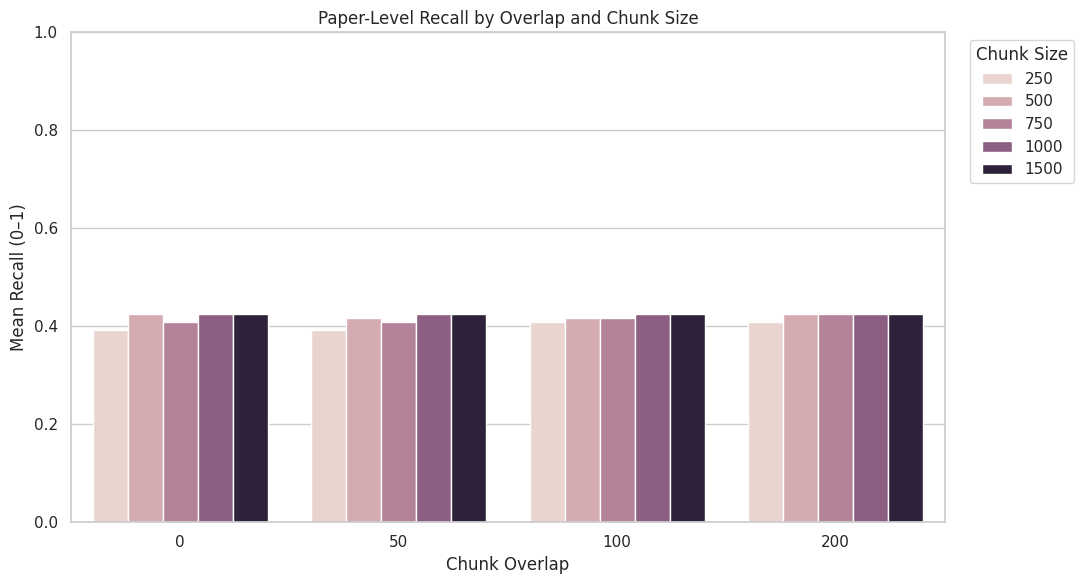

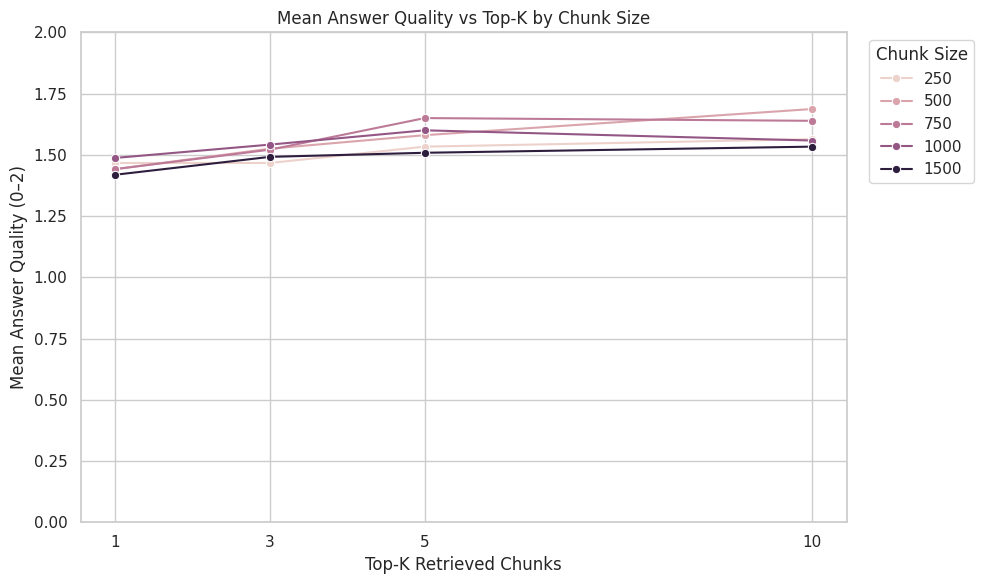


CELL 5 COMPLETE
Configurations plotted: 80
Graphs saved: /content/drive/MyDrive/RAG project/evaluation_plots
Compact summary saved: /content/drive/MyDrive/RAG project/module_4_visualization_summary.csv

Generated graph files:
 - answer_quality_overlap.png
 - answer_quality_vs_topk.png
 - context_size_vs_topk.png
 - hallucination_vs_topk.png
 - recall_by_overlap.png
 - recall_vs_topk.png


In [29]:

# CELL 5 — Visual Plots & Chart Generation

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --------------------------------------------------
# 1. Paths and load the corrected Cell 4 outputs
# --------------------------------------------------
OUT_DIR = "/content/drive/MyDrive/RAG project"
PLOT_DIR = os.path.join(OUT_DIR, "evaluation_plots")
os.makedirs(PLOT_DIR, exist_ok=True)

SUMMARY_PATH = os.path.join(OUT_DIR, "module_4_summary_results.csv")
DETAIL_PATH = os.path.join(OUT_DIR, "module_4_evaluation_results.csv")

if not os.path.exists(SUMMARY_PATH):
    raise FileNotFoundError(
        f"Summary file not found: {SUMMARY_PATH}. Run Cell 4 first."
    )
if not os.path.exists(DETAIL_PATH):
    raise FileNotFoundError(
        f"Detailed results not found: {DETAIL_PATH}. Run Cell 4 first."
    )

summary_df = pd.read_csv(SUMMARY_PATH)
eval_df = pd.read_csv(DETAIL_PATH)

required_summary = [
    "config_id", "chunk_size", "overlap", "top_k",
    "mean_recall", "mean_answer_quality",
    "hallucination_percentage", "mean_context_length"
]
missing = [c for c in required_summary if c not in summary_df.columns]
if missing:
    raise ValueError(f"Summary CSV is missing columns: {missing}")

print("Configurations:", summary_df["config_id"].nunique())
print("Plots will be saved to:", PLOT_DIR)

sns.set_theme(style="whitegrid")

# Consistent ordering across plots
chunk_order = sorted(summary_df["chunk_size"].dropna().unique())
overlap_order = sorted(summary_df["overlap"].dropna().unique())
topk_order = sorted(summary_df["top_k"].dropna().unique())

# --------------------------------------------------
# 2. Plot 1 — Recall@K vs Top-K by chunk size
# --------------------------------------------------
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=summary_df,
    x="top_k",
    y="mean_recall",
    hue="chunk_size",
    hue_order=chunk_order,
    marker="o",
    errorbar=None
)
plt.title("Paper-Level Recall vs Top-K by Chunk Size")
plt.xlabel("Top-K Retrieved Chunks")
plt.ylabel("Mean Recall (0–1)")
plt.xticks(topk_order)
plt.ylim(0, 1)
plt.legend(title="Chunk Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "recall_vs_topk.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 3. Plot 2 — Answer quality across overlap and chunk size
# --------------------------------------------------
plt.figure(figsize=(11, 6))
sns.barplot(
    data=summary_df,
    x="overlap",
    y="mean_answer_quality",
    hue="chunk_size",
    hue_order=chunk_order,
    order=overlap_order,
    errorbar=None
)
plt.title("Mean Answer Quality by Overlap and Chunk Size")
plt.xlabel("Chunk Overlap")
plt.ylabel("Mean Answer Quality (0–2)")
plt.ylim(0, 2)
plt.legend(title="Chunk Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "answer_quality_overlap.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 4. Plot 3 — Hallucination rate vs Top-K
# --------------------------------------------------
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=summary_df,
    x="top_k",
    y="hallucination_percentage",
    hue="overlap",
    hue_order=overlap_order,
    marker="s",
    errorbar=None
)
plt.title("Judge-Flagged Hallucination Rate vs Top-K")
plt.xlabel("Top-K Retrieved Chunks")
plt.ylabel("Flagged Answers (%)")
plt.xticks(topk_order)
plt.ylim(bottom=0)
plt.legend(title="Overlap", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "hallucination_vs_topk.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 5. Plot 4 — Retrieved context size vs Top-K
# --------------------------------------------------
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=summary_df,
    x="top_k",
    y="mean_context_length",
    hue="chunk_size",
    hue_order=chunk_order,
    marker="^",
    errorbar=None
)
plt.title("Retrieved Context Length vs Top-K")
plt.xlabel("Top-K Retrieved Chunks")
plt.ylabel("Mean Context Length (Characters)")
plt.xticks(topk_order)
plt.legend(title="Chunk Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "context_size_vs_topk.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 6. Plot 5 — Recall by overlap and chunk size
# --------------------------------------------------
plt.figure(figsize=(11, 6))
sns.barplot(
    data=summary_df,
    x="overlap",
    y="mean_recall",
    hue="chunk_size",
    hue_order=chunk_order,
    order=overlap_order,
    errorbar=None
)
plt.title("Paper-Level Recall by Overlap and Chunk Size")
plt.xlabel("Chunk Overlap")
plt.ylabel("Mean Recall (0–1)")
plt.ylim(0, 1)
plt.legend(title="Chunk Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "recall_by_overlap.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 7. Plot 6 — Answer quality by Top-K
# --------------------------------------------------
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=summary_df,
    x="top_k",
    y="mean_answer_quality",
    hue="chunk_size",
    hue_order=chunk_order,
    marker="o",
    errorbar=None
)
plt.title("Mean Answer Quality vs Top-K by Chunk Size")
plt.xlabel("Top-K Retrieved Chunks")
plt.ylabel("Mean Answer Quality (0–2)")
plt.xticks(topk_order)
plt.ylim(0, 2)
plt.legend(title="Chunk Size", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "answer_quality_vs_topk.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 8. Export a compact experimental summary
# --------------------------------------------------
compact_cols = [
    "config_id", "chunk_size", "overlap", "top_k",
    "mean_recall", "recall_scored",
    "mean_answer_quality", "quality_scored",
    "hallucination_percentage", "hallucination_scored",
    "mean_context_length", "mean_context_words"
]
compact_cols = [c for c in compact_cols if c in summary_df.columns]

compact_summary = summary_df[compact_cols].copy()
compact_summary.to_csv(
    os.path.join(OUT_DIR, "module_4_visualization_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nCELL 5 COMPLETE")
print("Configurations plotted:", len(summary_df))
print("Graphs saved:", PLOT_DIR)
print("Compact summary saved:",
      os.path.join(OUT_DIR, "module_4_visualization_summary.csv"))
print("\nGenerated graph files:")
for filename in sorted(os.listdir(PLOT_DIR)):
    if filename.endswith(".png"):
        print(" -", filename)


In [30]:
print(
    summary_df[
        ["chunk_size", "overlap", "top_k", "mean_context_length"]
    ].sort_values(["chunk_size", "overlap", "top_k"]).head(20)
)

    chunk_size  overlap  top_k  mean_context_length
0          250        0      1           959.833333
1          250        0      3          3031.600000
2          250        0      5          5100.100000
3          250        0     10         10422.566667
4          250       50      1          1013.800000
5          250       50      3          3204.633333
6          250       50      5          5222.466667
7          250       50     10         10419.266667
8          250      100      1           926.233333
9          250      100      3          3034.033333
10         250      100      5          5138.366667
11         250      100     10         10355.300000
12         250      200      1          1000.433333
13         250      200      3          2845.666667
14         250      200      5          5022.066667
15         250      200     10         10416.000000
16         500        0      1          1462.633333
17         500        0      3          4371.100000
18         5

In [31]:

# FINAL CELL — Export and download evaluation outputs

import os
import pandas as pd
from google.colab import files

# --------------------------------------------------
# 1. Paths — consistent with Cells 3, 4 and 5
# --------------------------------------------------
OUT_DIR = "/content/drive/MyDrive/RAG project"
PLOT_DIR = os.path.join(OUT_DIR, "evaluation_plots")
os.makedirs(OUT_DIR, exist_ok=True)

RAG_PATH = os.path.join(OUT_DIR, "module_4_rag_judgements_v4.csv")
NO_RAG_PATH = os.path.join(OUT_DIR, "module_4_no_rag_judgements.csv")

DETAIL_PATH = os.path.join(OUT_DIR, "module_4_evaluation_results.csv")
SUMMARY_PATH = os.path.join(OUT_DIR, "module_4_summary_results.csv")
COMBINED_PATH = os.path.join(OUT_DIR, "module_4_rag_vs_no_rag_comparison.csv")
COMPARE_SUMMARY_PATH = os.path.join(
    OUT_DIR, "module_4_overall_comparison_summary.csv"
)
CONFIG_SUMMARY_PATH = os.path.join(
    OUT_DIR, "module_4_configuration_summary.csv"
)
VIS_SUMMARY_PATH = os.path.join(
    OUT_DIR, "module_4_visualization_summary.csv"
)

# --------------------------------------------------
# 2. Check required source files
# --------------------------------------------------
for path in [RAG_PATH, NO_RAG_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required judging file not found: {path}\n"
            "Check that the current V4 RAG and no-RAG judging cells have run."
        )

rag_df = pd.read_csv(RAG_PATH)
no_rag_df = pd.read_csv(NO_RAG_PATH)

# Normalize V4 RAG judge names if necessary
rename_map = {
    "answer_quality": "rag_answer_quality",
    "hallucination": "rag_hallucination",
    "reason": "rag_judge_reason"
}
for old, new in rename_map.items():
    if old in rag_df.columns and new not in rag_df.columns:
        rag_df.rename(columns={old: new}, inplace=True)

required_rag = ["query", "config_id", "rag_answer_quality", "rag_hallucination"]
required_no_rag = ["query", "no_rag_answer_quality", "no_rag_hallucination"]

for col in required_rag:
    if col not in rag_df.columns:
        raise ValueError(f"RAG file is missing column: {col}")

for col in required_no_rag:
    if col not in no_rag_df.columns:
        raise ValueError(f"No-RAG file is missing column: {col}")

# Convert scores to numeric; invalid/unresolved scores remain missing
for col in ["rag_answer_quality", "rag_hallucination"]:
    rag_df[col] = pd.to_numeric(rag_df[col], errors="coerce")

for col in ["no_rag_answer_quality", "no_rag_hallucination"]:
    no_rag_df[col] = pd.to_numeric(no_rag_df[col], errors="coerce")

# --------------------------------------------------
# 3. Build a one-row-per-question no-RAG baseline
# --------------------------------------------------
no_rag_scores = no_rag_df[
    ["query", "no_rag_answer_quality", "no_rag_hallucination"]
].drop_duplicates()

if no_rag_scores["query"].duplicated().any():
    raise ValueError(
        "Conflicting duplicate no-RAG scores exist for a question. "
        "Check the no-RAG judgement CSV before exporting."
    )

# --------------------------------------------------
# 4. Refresh RAG-vs-no-RAG comparison
# --------------------------------------------------
# Remove old baseline columns if this file already contains them.
rag_for_merge = rag_df.drop(
    columns=[
        c for c in [
            "no_rag_answer_quality", "no_rag_hallucination"
        ] if c in rag_df.columns
    ]
)

comparison_df = rag_for_merge.merge(
    no_rag_scores,
    on="query",
    how="left",
    validate="many_to_one",
    indicator=True
)

unmatched = (comparison_df["_merge"] != "both").sum()
comparison_df.drop(columns=["_merge"], inplace=True)

comparison_df.to_csv(
    COMBINED_PATH, index=False, encoding="utf-8-sig"
)

# --------------------------------------------------
# 5. Overall comparison
# --------------------------------------------------
overall_df = pd.DataFrame({
    "method": ["LLM only (no-RAG)", "RAG + LLM"],
    "mean_answer_quality": [
        no_rag_scores["no_rag_answer_quality"].mean(),
        rag_df["rag_answer_quality"].mean()
    ],
    "scored_answers": [
        no_rag_scores["no_rag_answer_quality"].count(),
        rag_df["rag_answer_quality"].count()
    ],
    "hallucination_flag_rate": [
        no_rag_scores["no_rag_hallucination"].mean(),
        rag_df["rag_hallucination"].mean()
    ],
    "hallucination_scored": [
        no_rag_scores["no_rag_hallucination"].count(),
        rag_df["rag_hallucination"].count()
    ]
})

overall_df.to_csv(
    COMPARE_SUMMARY_PATH, index=False, encoding="utf-8-sig"
)

# --------------------------------------------------
# 6. Confirm outputs from Cells 4 and 5
# --------------------------------------------------
expected_outputs = [
    DETAIL_PATH,
    SUMMARY_PATH,
    CONFIG_SUMMARY_PATH,
    VIS_SUMMARY_PATH
]

missing_outputs = [p for p in expected_outputs if not os.path.exists(p)]

if missing_outputs:
    print("Some analysis outputs are missing:")
    for path in missing_outputs:
        print(" -", path)
    print("Run the relevant analysis cell(s) before final export.")
else:
    print("Cell 4 and Cell 5 analysis outputs are present.")

# --------------------------------------------------
# 7. Print export checks
# --------------------------------------------------
print("\nEXPORT SUMMARY")
print("RAG experiment rows:", len(rag_df))
print("Unique no-RAG questions:", no_rag_scores["query"].nunique())
print("Unique RAG configurations:", rag_df["config_id"].nunique())
print("Unmatched RAG rows in comparison:", unmatched)
print("Valid RAG quality scores:", rag_df["rag_answer_quality"].count())
print("Unresolved RAG quality scores:", rag_df["rag_answer_quality"].isna().sum())
print("Valid no-RAG quality scores:", no_rag_scores["no_rag_answer_quality"].count())

print("\nOverall comparison:")
display(overall_df)

# --------------------------------------------------
# 8. List saved outputs and graphs
# --------------------------------------------------
output_paths = [
    RAG_PATH,
    NO_RAG_PATH,
    DETAIL_PATH,
    SUMMARY_PATH,
    COMBINED_PATH,
    COMPARE_SUMMARY_PATH,
    CONFIG_SUMMARY_PATH,
    VIS_SUMMARY_PATH
]

print("\nSaved output files:")
for path in output_paths:
    print(
        os.path.basename(path),
        "| exists:", os.path.exists(path)
    )

if os.path.isdir(PLOT_DIR):
    plots = sorted(
        os.path.join(PLOT_DIR, f)
        for f in os.listdir(PLOT_DIR)
        if f.lower().endswith(".png")
    )
    print("\nSaved graphs:", len(plots))
    for path in plots:
        print(" -", os.path.basename(path))

# --------------------------------------------------
# 9. Download main deliverables
# --------------------------------------------------
download_paths = [
    DETAIL_PATH,
    SUMMARY_PATH,
    COMBINED_PATH,
    COMPARE_SUMMARY_PATH,
    CONFIG_SUMMARY_PATH,
    VIS_SUMMARY_PATH
]

print("\nStarting downloads...")
for path in download_paths:
    if os.path.exists(path):
        files.download(path)
    else:
        print("Skipped missing file:", path)

print("\nFINAL EXPORT CELL COMPLETE")


Cell 4 and Cell 5 analysis outputs are present.

EXPORT SUMMARY
RAG experiment rows: 2400
Unique no-RAG questions: 30
Unique RAG configurations: 80
Unmatched RAG rows in comparison: 0
Valid RAG quality scores: 2390
Unresolved RAG quality scores: 10
Valid no-RAG quality scores: 30

Overall comparison:


,method,mean_answer_quality,scored_answers,hallucination_flag_rate,hallucination_scored
0,LLM only (no-RAG),0.600000,30,0.000000,30
1,RAG + LLM,1.532636,2390,0.003766,2390



Saved output files:
module_4_rag_judgements_v4.csv | exists: True
module_4_no_rag_judgements.csv | exists: True
module_4_evaluation_results.csv | exists: True
module_4_summary_results.csv | exists: True
module_4_rag_vs_no_rag_comparison.csv | exists: True
module_4_overall_comparison_summary.csv | exists: True
module_4_configuration_summary.csv | exists: True
module_4_visualization_summary.csv | exists: True

Saved graphs: 6
 - answer_quality_overlap.png
 - answer_quality_vs_topk.png
 - context_size_vs_topk.png
 - hallucination_vs_topk.png
 - recall_by_overlap.png
 - recall_vs_topk.png

Starting downloads...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


FINAL EXPORT CELL COMPLETE
